# What is CNN?

CNN stands for Convolutional Neural Network. It works by splitting images into convolutions and then perform deep learning in that image.

CNN is used mostly in image classification. It is specifically designed for image data, capturing spatial patterns using:
1. Convolution (feature extraction)
2. Pooling (downsampling)
3. Fully connected layers (classification)

Why is CNN used for image detection instead of normal neural networks (ANN)?

1. ANN treats image as a 1D-vector -> loses spatial information
2. CNN preserves height x width x channel structure
3. Used shared weights -> fewer parameters to train -> less overfitting chances


Key Concepts:

1. Convolution Operation -> applying filters to detect the features.
2. Feature Maps -> outputs after applying filters
3. Stride and padding -> control how the filter moves
4. Pooling (Max/Average) -> reduce dimensionality
5. Activation Functions -> ReLU almost always used


In [ ]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

In [ ]:
(x_train,y_train) , (x_test,y_test) =cifar10.load_data()


x_train , x_test = x_train/255.0 , x_test/255.0

In [43]:
y_train=to_categorical(y_train)
y_test=to_categorical(y_test)


In [44]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D

In [45]:
model=Sequential([
    #Input layer
    Conv2D(32,(3,3),activation='relu',padding='same',input_shape=(32,32,3)),
    MaxPooling2D((2,2)), # Reduce the dimension of the image from 32x32 to 16x16,

    Conv2D(32,(3,3),activation='relu',padding='same'),
    MaxPooling2D((2,2)), # Reduce the dimension of the image from 16x16 to 8x8

    Flatten(),

    Dense(32,activation='relu'), #Hidden Layer
    Dense(10,activation='softmax') # Output Layer

])

c:\Users\saura\Documents\Python\python_55_days_programs\deep_learning\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [46]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [47]:
history=model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test,y_test)
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.4368 - loss: 1.5621 - val_accuracy: 0.5321 - val_loss: 1.3091
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.5723 - loss: 1.2117 - val_accuracy: 0.5973 - val_loss: 1.1412
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6216 - loss: 1.0819 - val_accuracy: 0.6244 - val_loss: 1.0723
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6544 - loss: 0.9932 - val_accuracy: 0.6398 - val_loss: 1.0211
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6745 - loss: 0.9381 - val_accuracy: 0.6594 - val_loss: 0.9677
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6912 - loss: 0.8863 - val_accuracy: 0.6728 - val_loss: 0.9273
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.7039 - loss: 0.8537 - val_accuracy: 0.6745 - val_loss: 0.9547
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.7163 - loss: 0.8193 - 

In [48]:
history.history

{'accuracy': [0.4367600083351135,
  0.5723199844360352,
  0.6216400265693665,
  0.6543999910354614,
  0.6744999885559082,
  0.6911600232124329,
  0.7039399743080139,
  0.7163400053977966,
  0.728380024433136,
  0.7369999885559082],
 'loss': [1.56208074092865,
  1.2116609811782837,
  1.0818780660629272,
  0.993208646774292,
  0.9380620121955872,
  0.886283814907074,
  0.8536543250083923,
  0.8192859292030334,
  0.7862877249717712,
  0.7602182030677795],
 'val_accuracy': [0.5321000218391418,
  0.5972999930381775,
  0.6244000196456909,
  0.6398000121116638,
  0.6593999862670898,
  0.6728000044822693,
  0.6744999885559082,
  0.6895999908447266,
  0.6858000159263611,
  0.6823999881744385],
 'val_loss': [1.3090558052062988,
  1.1412287950515747,
  1.0723259449005127,
  1.0211436748504639,
  0.9676680564880371,
  0.9272862076759338,
  0.954694926738739,
  0.902031660079956,
  0.9085733294487,
  0.9230172634124756]}

Text(0.5, 1.0, 'CIFAR-10 Data Training and Validation Loss')

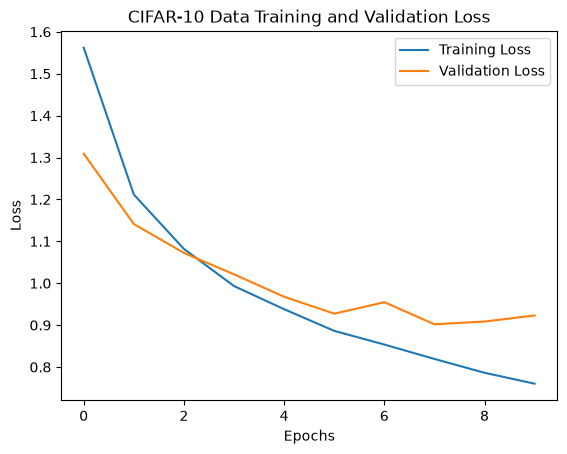

In [49]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CIFAR-10 Data Training and Validation Loss")